In [11]:
from typing import TypedDict, Annotated, Optional
from langgraph.graph import add_messages, StateGraph, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.checkpoint.memory import MemorySaver
from uuid import uuid4
import json

load_dotenv()

model = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

In [12]:
search_tool = TavilySearchResults(max_results=4)

tools = [search_tool]

memory = MemorySaver()

In [13]:
llm_with_tools = model.bind_tools(tools=tools)

In [16]:
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage

class State(TypedDict):
    messages: Annotated[list, add_messages]

async def model(state: State):
    result = await llm_with_tools.ainvoke(state["messages"])
    return {
        "messages": [result],
    }

async def tools_router(state: State):
    last_message = state["messages"][-1]

    if(hasattr(last_message, "tool_calls") and len(last_message.tool_calls) > 0):
        return "tool_node"
    else:
        return END
    
async def tool_node(state):
    """Custom tool node that handles tool calls from the LLM"""
    # Get the tool calls from the alst message
    tool_calls = state["messages"][-1].tool_calls

    # Initialize list to store tool messages
    tools_messages = []

    # Process each tool call
    for tool_call in tool_calls:
        tool_name = tool_call["name"]
        tool_args = tool_call["args"]
        tool_id = tool_call["id"]

        # Handl the search tool
        if tool_name == "tavily_search_results_json":
            #Execute the search tool with the provided arguments
            search_results = await search_tool.ainvoke(tool_args)

            # Create a ToolMessage for this result
            tool_message = ToolMessage(
                content=str(search_results),
                tool_call_id=tool_id,
                name=tool_name
            )

            tools_messages.append(tool_message)

    # Add the toiol messags to the state
    return {"messages": tools_messages}

graph_builder = StateGraph(State)

graph_builder.add_node("model", model)
graph_builder.add_node("tool_node", tool_node)
graph_builder.set_entry_point("model")

graph_builder.add_conditional_edges(
    "model", 
    tools_router,
    {
        "tool_node": "tool_node",
        END: END,
    })

graph_builder.add_edge("tool_node", "model")

graph = graph_builder.compile(checkpointer=memory)

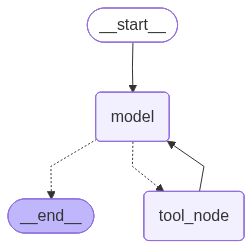

In [17]:
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod

display(
    Image(
        graph.get_graph().draw_mermaid_png(
            draw_method=MermaidDrawMethod.API
        )
    )
)

In [18]:
config = {
    "configurable": {
        "thread_id": 5
    }
}

response = await graph.ainvoke({
    "messages": [HumanMessage(content="When is the next spacex launch?")]
}, config=config)

response

{'messages': [HumanMessage(content='When is the next spacex launch?', additional_kwargs={}, response_metadata={}, id='887569c7-2171-4cda-a71a-63e283c7a978'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'tavily_search_results_json', 'arguments': '{"query": "next SpaceX launch"}'}, '__gemini_function_call_thought_signatures__': {'7723fe5e-094b-4d85-b3b2-1eed060c9457': 'CqUCAXLI2nzlKsvSr3OrAFRtjz8V3OqZnoepbcoVZys9x8xFiEtCGIrM9C1bgVHnH27oBKEv4Qcch3aw1mEcblVZZFbnfHf2YcWm3tRSu0XukPHQYIgJUYrWXaYNbpBUithFlpVJUb9xyxOV3xSon+aySZFgPWZBzH2l5S0FqImZ8B9n8mL6hxd1X7499wrnMIVgTsixwLoZyj3FDQLrzViK+GMOLboFs0PyZ20vztS+cbcDKQD1PNa4+v/2196HftAoECqOCT3ccrIBiN453q/+jFyuoRf8UI7zlyeFCi7uUd2qy5IORbKh51z2+JDWFX2Gw+ACBUNgFYGglQ0t7A6dEIlIc8uaICJIIsbeX2xAnHCgUlI5TcEHys0YiDZsZjCW0Qm1AVc='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019bf442-3ad7-7111-895b-aa0f16015bf8-0', tool_calls=[{'na

In [19]:
config = {
    "configurable": {
        "thread_id": 7
    }
}

async for event in graph.astream_events({
    "messages": [HumanMessage(content="Give me a 100 word essay on climate change")],
}, config=config, version="v2"):
    if event["event"] == "on_chat_model_stream":
        print(event["data"]["chunk"].content, end="", flush=True)

[{'type': 'text', 'text': 'Climate change, a pressing global crisis, refers to long-term shifts in temperatures and weather patterns. Primarily', 'extras': {'signature': 'CksBcsjafE1kSDajLFbFRn0vArdr4v/qCDFTc1QCSw0aQ79v8QGad0kTnMj8dT+zvvVPQByMXTGrKpgOCSn0aJFs0FfqHUh3xEzHRpQKoAEBcsjafLVx9sz3bPnFC8DQ4Fh8p61EXoSItOcgL2OIOLMyAv/gwQx7W6zlD26fDi9pavWTEjDokECPHCjsfXSSetkbU2OmYS8WOEr6x4dUgetq6l/YK2L53pZpyvpolSC7CDKsAiPeedFEQzUX7Za+22zBJ9OQSqCihmqs47TxAQeViJu03xm9vaOsrO93OilrqQLbDpgrYp06BC/DTYZW'}, 'index': 0}] driven by human activities, particularly the burning of fossil fuels, it releases greenhouse gases that trap heat in the atmosphere. This leads to a cascade of detrimental effects: rising global temperatures, melting glaciers and ice caps, and increasingly frequent and intense extreme weather events like heatwaves, droughts, floods, and wildfires. The consequences are far-reaching, threatening ecosystems, biodiversity, food security, and human health. Addressing climate change necessitat

In [20]:
config = {
    "configurable": {
        "thread_id": 8
    }
}

async for event in graph.astream_events({
    "messages": [HumanMessage(content="When is the next spacex launch?")],
}, config=config, version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='When is the next spacex launch?', additional_kwargs={}, response_metadata={})]}}, 'name': 'LangGraph', 'tags': [], 'run_id': '019bf442-f997-7870-97ad-585ee1684acb', 'metadata': {'thread_id': 8}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='When is the next spacex launch?', additional_kwargs={}, response_metadata={}, id='b9878053-b07e-4724-989f-1dcacfb35bae')]}}, 'name': 'model', 'tags': ['graph:step:1'], 'run_id': '019bf442-f999-7131-94c5-c1da0bfe48e4', 'metadata': {'thread_id': 8, 'langgraph_step': 1, 'langgraph_node': 'model', 'langgraph_triggers': ('branch:to:model',), 'langgraph_path': ('__pregel_pull', 'model'), 'langgraph_checkpoint_ns': 'model:1625a6e5-b187-5e65-b060-9d2e2d1e6e2f'}, 'parent_ids': ['019bf442-f997-7870-97ad-585ee1684acb']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[HumanMessage(content='When is the next spa